# Figure S9 - Inferred hydrodynamic radii for 144 proteins, with DDX4<sup>[1-245]</sup> overlaid

**What the figure shows.** A scatter of inferred hydrodynamic radius against chain length for a compilation of disordered proteins whose radii of gyration have been measured by small-angle X-ray scattering (red points), with two DDX4<sup>[1-245]</sup> values from this work superimposed: the monomer under **non-phase-separating** conditions (4.2 nm) and under **phase-separating** conditions (1.6 nm).

**Why it matters.** The red cloud is the expected relationship - disordered proteins get larger as they get longer, following a well-behaved power law. The non-phase-separating DDX4 point at 4.2 nm sits comfortably inside that cloud for a 245-residue chain, exactly where an ordinary disordered protein of that length belongs.

The phase-separating point at 1.6 nm does not. At 245 residues it falls dramatically below the trend - it is more compact than proteins less than a quarter its length. This is the visual statement of the paper's central structural claim: on crossing the binodal, DDX4<sup>[1-245]</sup> collapses into a state far more compact than anything a disordered chain of that length would ordinarily adopt. The main text makes the same point by comparison with mCherry, a folded protein of comparable molecular weight with an $R_h$ of 1.4 nm, and with a scaling law for densely compacted proteins that predicts 1.6 nm.

**How it is made.** The compilation of SAXS-derived $R_g$ values is from Alston *et al.* (2023). Each is converted to an inferred $R_h$ using the empirical relationship of Nygaard *et al.* (2017), with the chain length taken from that protein's own sequence, and plotted against length. The two DDX4 points come from the DLS measurements in Figure 3 of this paper.

Using the Nygaard conversion here is the consistent choice: the DDX4 values being overlaid are DLS measurements, and Figure S8 shows that this is the estimator that agrees with DLS.

## What is in this directory

| path | contents |
|------|----------|
| `data/IDR_dimensions.csv` | the compiled SAXS-derived radii of gyration and sequences |
| `data/README.md` | provenance of that compilation |
| `figures/` | output; the notebook writes `figure_S9_inferred_rh.pdf` and `.png` |

Everything this figure needs is in this directory - it uses none of the bulk simulation data. The only dependencies are `numpy` and `matplotlib`.

## Setup

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Holehouse lab figure defaults (December 2024)
# ---------------------------------------------------------------------------

# export PDF/PS fonts as TrueType so text stays editable in Illustrator/Affinity
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

matplotlib.rcParams['axes.linewidth'] = 0.5
matplotlib.rcParams['lines.linewidth'] = 0.8

matplotlib.rcParams['xtick.major.size'] = 2
matplotlib.rcParams['xtick.minor.size'] = 0.5
matplotlib.rcParams['ytick.major.size'] = 2
matplotlib.rcParams['ytick.minor.size'] = 0.5
matplotlib.rcParams['xtick.major.width'] = 0.375
matplotlib.rcParams['ytick.major.width'] = 0.375
matplotlib.rcParams['xtick.minor.width'] = 0.375
matplotlib.rcParams['ytick.minor.width'] = 0.375
matplotlib.rcParams['xtick.major.pad'] = 1
matplotlib.rcParams['ytick.major.pad'] = 1

matplotlib.rcParams['xtick.labelsize'] = 8
matplotlib.rcParams['ytick.labelsize'] = 8
matplotlib.rcParams['axes.labelsize'] = 10
matplotlib.rcParams['legend.fontsize'] = 8

# The manuscript figures used Arial; the fallbacks let this run anywhere.
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import csv
import os

os.makedirs('figures', exist_ok=True)

## The data

`data/IDR_dimensions.csv` is a compilation of disordered proteins for which a radius of gyration has been measured by SAXS, taken from Alston *et al.* (2023). Each row carries the protein name, its UniProt accession, the measured $R_g$ with its error, and the sequence of the region that was measured.

The sequence matters as much as the $R_g$ here: the Nygaard conversion is chain-length dependent, so each protein's length has to come from its own sequence rather than from any global assumption.

In [2]:
with open('data/IDR_dimensions.csv', encoding='utf-8-sig') as fh:
    rows = list(csv.DictReader(fh))

def as_float(value):
    """
    Parse a CSV field as a float, returning nan where the field is blank.

    Ten entries in the compilation have no reported error on the radius of
    gyration. Those are read as nan rather than being dropped, since the
    radius of gyration itself is present for every entry.

    Parameters
    ----------
    value : str
        The raw field as read from the CSV.

    Returns
    -------
    float
        The parsed value, or nan if the field is empty.
    """

    value = value.strip()

    return float(value) if value else float('nan')


names = [row['Name'].strip() for row in rows]
sequences = [row['Seq'].strip() for row in rows]
rg = np.array([as_float(row['Rg (Å)']) for row in rows])
rg_error = np.array([as_float(row['Error (Å)']) for row in rows])
lengths = np.array([len(sequence) for sequence in sequences])

print(f'{len(rows)} entries')
print(f'chain lengths : {lengths.min()} - {lengths.max()} residues')
print(f'Rg            : {rg.min():.1f} - {rg.max():.1f} Angstroms')
print(f'entries with no reported error on Rg: {int(np.isnan(rg_error).sum())} '
      f'(the error is not used in this figure)')

145 entries
chain lengths : 15 - 698 residues
Rg            : 9.1 - 79.0 Angstroms
entries with no reported error on Rg: 10 (the error is not used in this figure)


## Converting $R_g$ to $R_h$

The same Nygaard *et al.* (2017) relationship used in Figure S2, in which the ratio $R_g/R_h$ is itself a function of $R_g$ and chain length $N$:

$$\frac{R_g}{R_h} = \frac{\alpha_1 (R_g - \alpha_2 N^{0.33})}{N^{0.60} - N^{0.33}} + \alpha_3$$

with $\alpha_1 = 0.216$, $\alpha_2 = 4.06$, $\alpha_3 = 0.821$. Here $N$ is read from each protein's own sequence, so the function takes the sequence rather than a hard-coded length.

As in Figure S2, this is written out rather than imported: SOURSOP implements the identical arithmetic as `SSProtein.get_hydrodynamic_radius(mode='nygaard')`, but that is a method on a trajectory object, and the input here is a table of scalar measurements with no coordinates attached.

In [3]:
def rg_to_rh(rg: float,
             sequence: str,
             alpha1: float = 0.216,
             alpha2: float = 4.06,
             alpha3: float = 0.821) -> float:
    """
    Convert a radius of gyration into an apparent hydrodynamic radius.

    Uses the empirical approximation derived by Nygaard et al. [1] (their
    equation 7), in which the ratio Rg/Rh depends on both the radius of
    gyration and the chain length. The chain length is taken from the
    supplied sequence, so each protein in the compilation is converted using
    its own length.

    Parameters
    ----------
    rg : float
        Radius of gyration of the chain, in Angstroms.

    sequence : str
        Amino acid sequence of the region the radius of gyration describes.
        Only its length is used.

    alpha1 : float
        First fit parameter in equation (7) of Nygaard et al. Default = 0.216.

    alpha2 : float
        Second fit parameter in equation (7) of Nygaard et al. Default = 4.06.

    alpha3 : float
        Third fit parameter in equation (7) of Nygaard et al. Default = 0.821.

    Returns
    -------
    float
        The inferred hydrodynamic radius, in the same units as `rg`.

    References
    ----------
    [1] Nygaard, M., B. B. Kragelund, E. Papaleo, and K. Lindorff-Larsen.
        2017. An Efficient Method for Estimating the Hydrodynamic Radius of
        Disordered Protein Conformations. Biophys. J. 113:550-557.
    """

    nres = len(sequence)

    # precompute the two chain-length terms
    N_033 = np.power(nres, 0.33)
    N_060 = np.power(nres, 0.60)

    rg_over_rh = ((alpha1 * (rg - alpha2 * N_033)) / (N_060 - N_033)) + alpha3

    return (1 / rg_over_rh) * rg

In [4]:
# Angstroms -> nanometres, matching the published axis
rh = np.array([rg_to_rh(rg[i], sequences[i]) for i in range(len(rg))]) / 10.0

print(f'inferred Rh : {rh.min():.2f} - {rh.max():.2f} nm')

# the two DDX4 values measured by DLS in this work (Figure 3)
DDX4_LENGTH = 245
DDX4_RH_NO_PS = 4.2    # non-phase-separating conditions
DDX4_RH_PS = 1.6       # phase-separating conditions

# how does the collapsed state compare with proteins of similar length?
similar = np.abs(lengths - DDX4_LENGTH) < 50
print(f'\n{similar.sum()} compilation proteins within 50 residues of DDX4 length:')
print(f'  inferred Rh {rh[similar].min():.2f} - {rh[similar].max():.2f} nm, mean {rh[similar].mean():.2f} nm')
print(f'  DDX4 non-phase-separating : {DDX4_RH_NO_PS} nm  (inside this range)')
print(f'  DDX4 phase-separating     : {DDX4_RH_PS} nm  (far below it)')

# the collapsed state is smaller than proteins a fraction of its length
smaller = lengths[rh < DDX4_RH_PS]
if len(smaller):
    print(f'\nonly {len(smaller)} compilation proteins have an inferred Rh below {DDX4_RH_PS} nm; '
          f'the longest is {smaller.max()} residues')

inferred Rh : 1.21 - 6.74 nm

10 compilation proteins within 50 residues of DDX4 length:
  inferred Rh 3.16 - 4.90 nm, mean 4.31 nm
  DDX4 non-phase-separating : 4.2 nm  (inside this range)
  DDX4 phase-separating     : 1.6 nm  (far below it)

only 4 compilation proteins have an inferred Rh below 1.6 nm; the longest is 24 residues


## The figure

Red points are the compilation; blue is DDX4 under non-phase-separating conditions and yellow under phase-separating conditions, both at 245 residues.

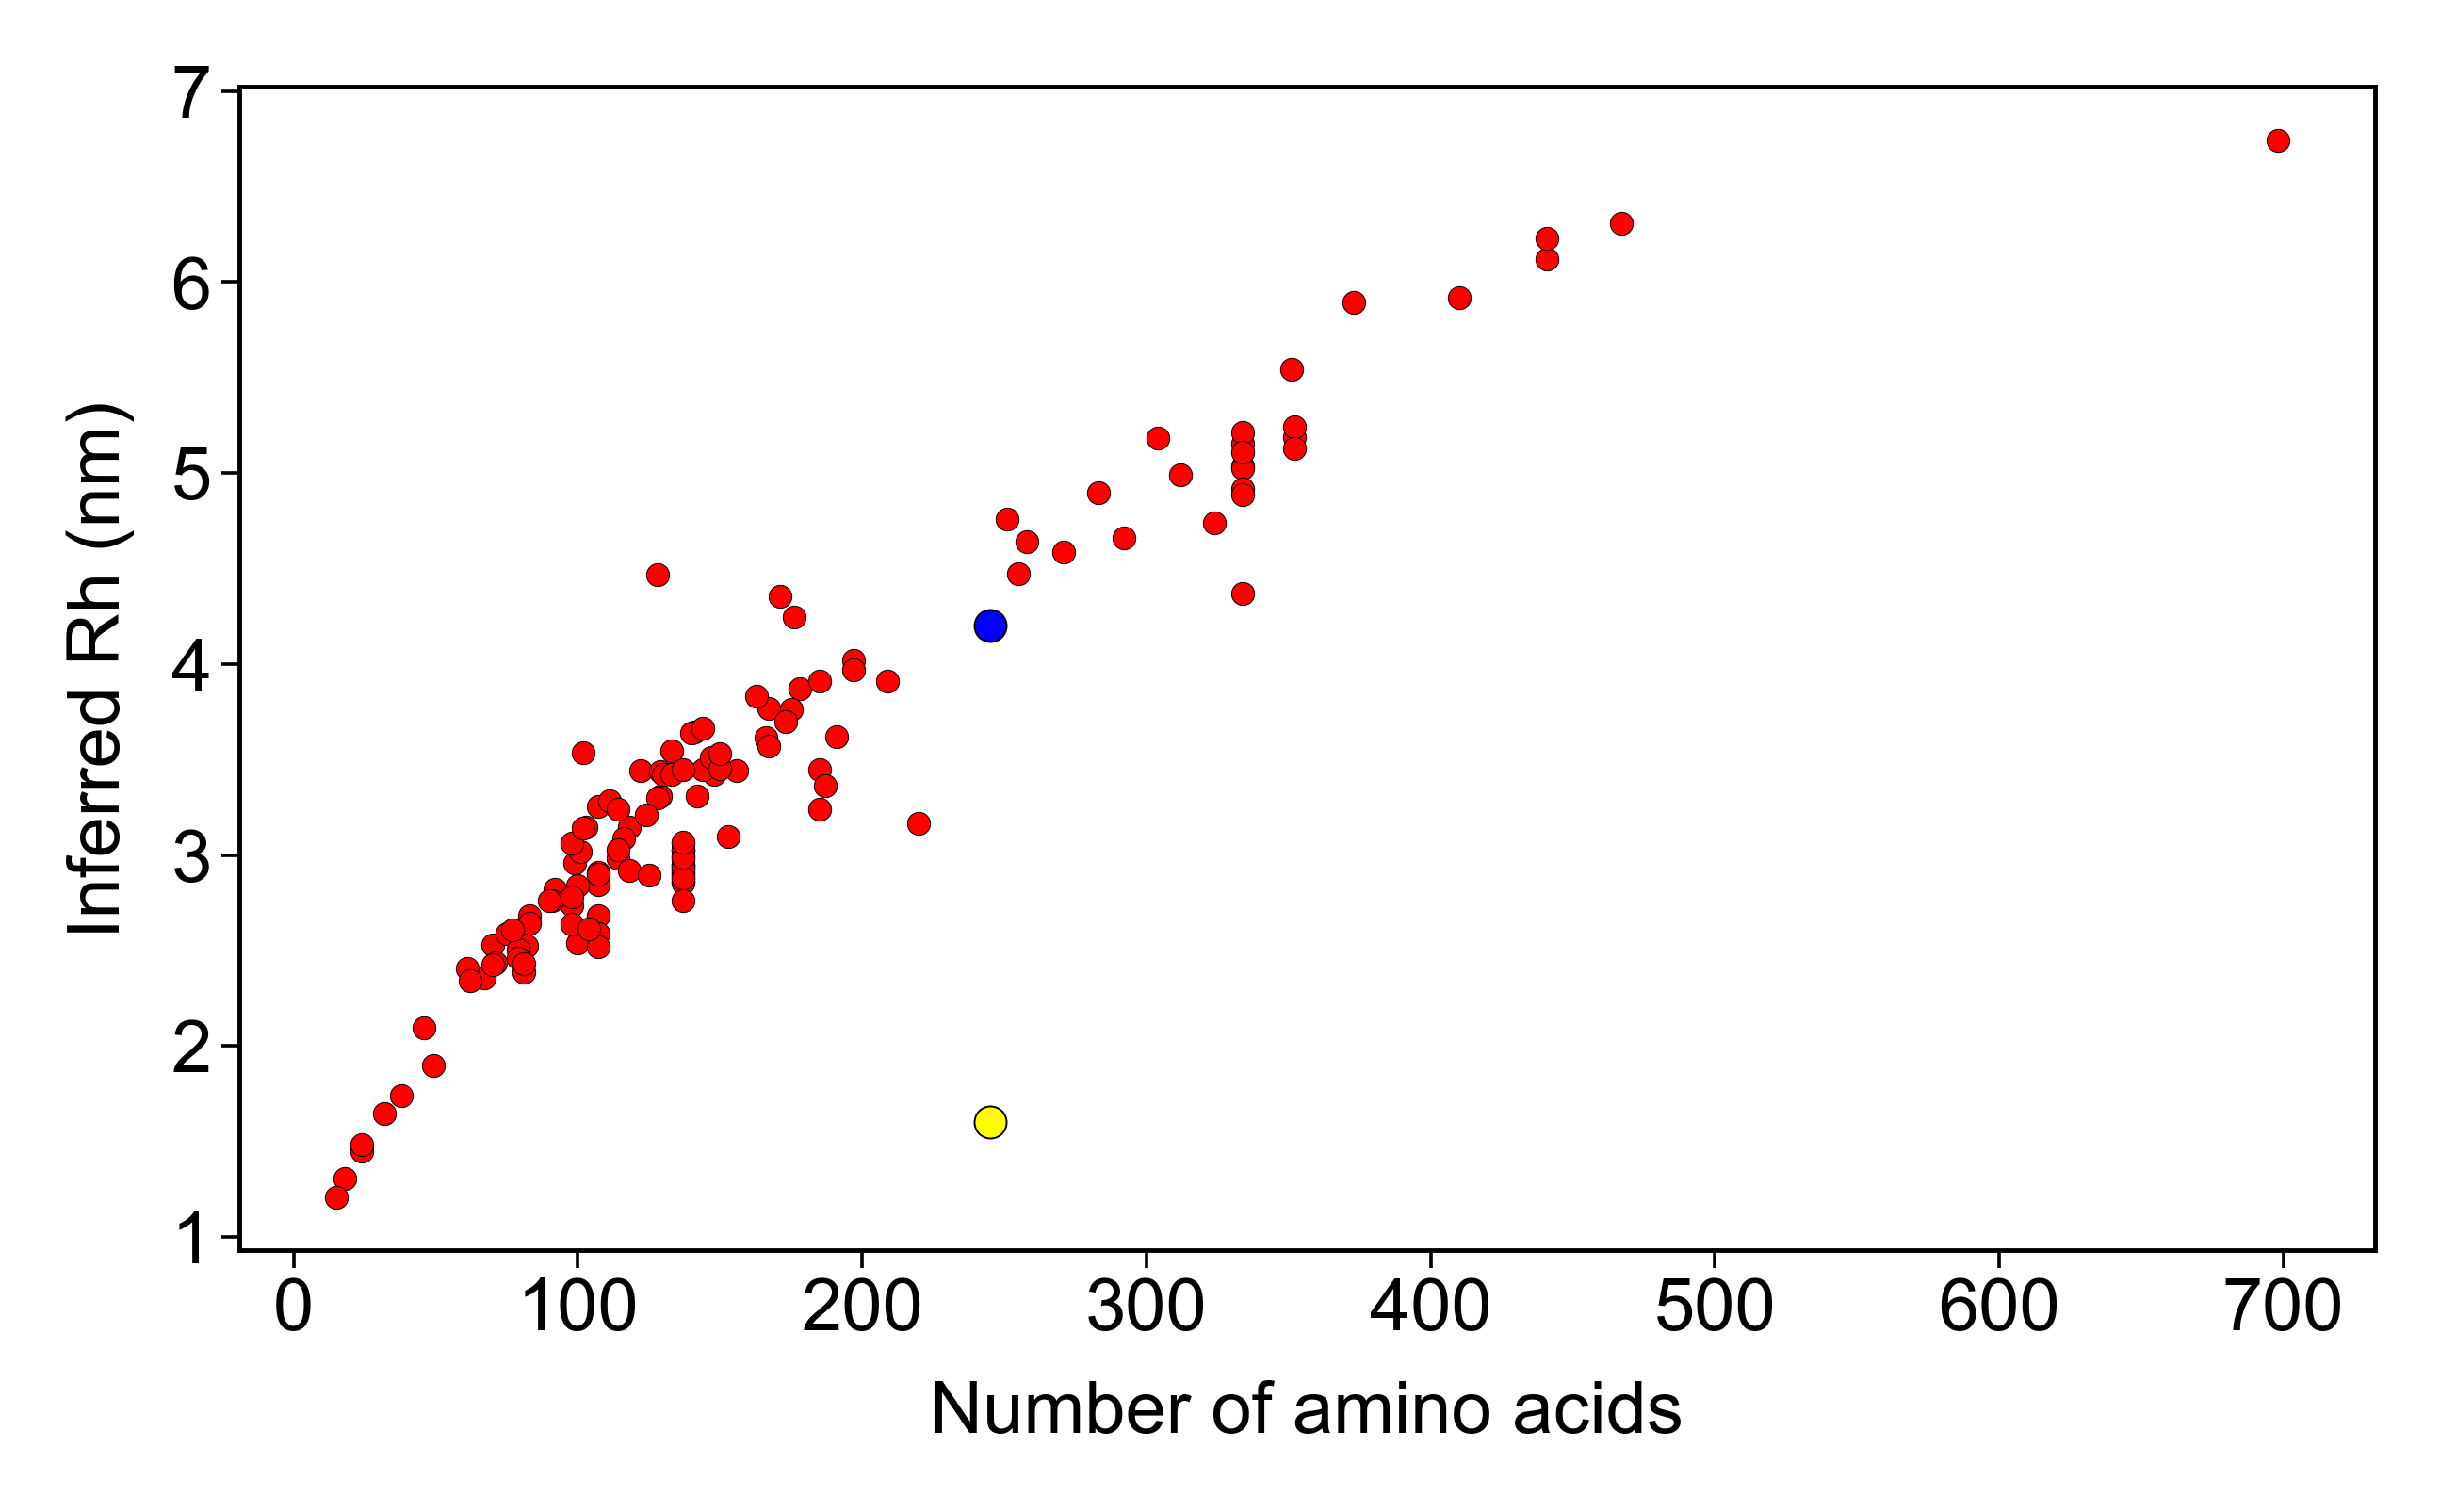

In [5]:
plt.figure(figsize=(3.8, 2.4), dpi=350)
ax = plt.gca()

ax.plot(lengths, rh, 'o', ms=2.5, mfc='r', mec='k', mew=0.1)

ax.plot(DDX4_LENGTH, DDX4_RH_NO_PS, 'o', ms=3.5, mfc='b', mec='k', mew=0.2)
ax.plot(DDX4_LENGTH, DDX4_RH_PS, 'o', ms=3.5, mfc='yellow', mec='k', mew=0.2)

ax.set_xlabel('Number of amino acids', fontsize=8)
ax.set_ylabel('Inferred Rh (nm)', fontsize=8)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

plt.tight_layout()
plt.savefig('figures/figure_S9_inferred_rh.pdf')
plt.savefig('figures/figure_S9_inferred_rh.png', dpi=350)
plt.show()

## Differences from the published figure

* **Annotation.** The published panel has the two DDX4 points labelled in text, with an arrow drawn between them, added in a vector graphics editor. The notebook plots the points only.
* **Colour of the collapsed-state point.** The original notebook draws the phase-separating point in yellow, which is what is reproduced here; the published panel shows it in dark green, recoloured during figure assembly.
* **Number of proteins.** The published caption says 144 proteins. `IDR_dimensions.csv` contains 145 entries, which is what the notebook plots. Seven pairs of entries share a sequence while being distinct measurements - phosphorylated and unphosphorylated forms of the same protein, and constructs recorded under two names - so the count depends on how those are treated.
* **Unused analytical reference.** The original notebook also computed an AFRC (analytical Flory random coil) radius of gyration for every sequence. Those values are not used in this figure, and the calculation - which is the slowest step in the original - has been dropped.
* **No pandas.** The original read the CSV with pandas; this uses the standard library `csv` module, which removes a dependency for a 145-row table.